In [1]:
import sys
import torch
sys.path.insert(0,"../src")

from cnn_project.train import train_model
from cnn_project.model import EuroSATModel
from cnn_project.evaluate import evaluate_model
from cnn_project.data import create_data_loaders
from pathlib import Path


First, select CUDA as the device, then initialize the model and prepare the data loaders.

This process usually takes around 20–30 seconds for the workers to become ready, even though the cell itself may appear to finish executing in 0 seconds.

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("The model is using CUDA")
else:
    device = torch.device("cpu")
    print("The model is using CPU")

torch.manual_seed(42)
model = EuroSATModel().to(device)
train_loader, val_loader, test_loader= create_data_loaders(batch_size=64, num_workers=10)


The model is using CUDA


First use the functions to train and then to evaluate the model

This takes around 3-4 minutes to complete

In [3]:
best_checkpoint_path = Path("../Checkpoints/eurosat_cnn_best.pt")
history = train_model(
    model=model, train_loader=train_loader, val_loader=val_loader, lr= 0.00633, gamma= 0.696,
    device=device, epochs=45, checkpoint_path=best_checkpoint_path
)
model.load_state_dict(torch.load(best_checkpoint_path, map_location=device, weights_only=True))
best_row = max(range(len(history["epoch"])), key=lambda i: history["val_accuracy"][i])
print(f"Using epoch {history['epoch'][best_row]} with validation accuracy "
      f"{history['val_accuracy'][best_row]:.2%}")
train_correct, train_total = evaluate_model(model=model, dataset_loader=train_loader, device=device)
val_correct, val_total = evaluate_model(model=model, dataset_loader=val_loader, device=device)
print(f"Train Accuracy: {100 * train_correct / train_total:.4f}%, "
      f"Val Accuracy: {100 * val_correct / val_total:.4f}%")


Training model...
Epoch 1, Loss: 1.1466, Accuracy: 0.5994, LR: 0.0063300000, Val loss: 0.8221, Val accuracy: 0.7067
Epoch 2, Loss: 0.7780, Accuracy: 0.7200, LR: 0.0063300000, Val loss: 1.8592, Val accuracy: 0.5704
Epoch 3, Loss: 0.6644, Accuracy: 0.7634, LR: 0.0063300000, Val loss: 0.5119, Val accuracy: 0.8141
Epoch 4, Loss: 0.5403, Accuracy: 0.8118, LR: 0.0044056800, Val loss: 0.5528, Val accuracy: 0.8133
Epoch 5, Loss: 0.5002, Accuracy: 0.8250, LR: 0.0044056800, Val loss: 0.4923, Val accuracy: 0.8200
Epoch 6, Loss: 0.4557, Accuracy: 0.8410, LR: 0.0044056800, Val loss: 0.4580, Val accuracy: 0.8433
Epoch 7, Loss: 0.3917, Accuracy: 0.8671, LR: 0.0030663533, Val loss: 0.3193, Val accuracy: 0.8889
Epoch 8, Loss: 0.3664, Accuracy: 0.8711, LR: 0.0030663533, Val loss: 0.3521, Val accuracy: 0.8696
Epoch 9, Loss: 0.3400, Accuracy: 0.8816, LR: 0.0030663533, Val loss: 0.7920, Val accuracy: 0.7944
Epoch 10, Loss: 0.3031, Accuracy: 0.8944, LR: 0.0021341819, Val loss: 0.5218, Val accuracy: 0.8400
E

Save the per-epoch metrics as CSV and plot training and validation curves. The dashed line marks the second training stage.

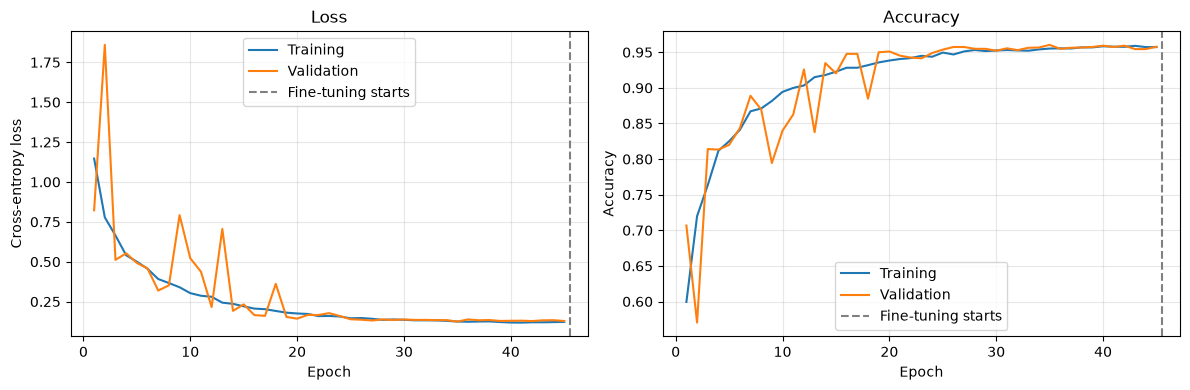

Saved history to ../Checkpoints/training_history2.csv


In [4]:
import csv
import matplotlib.pyplot as plt

history_path = Path("../Checkpoints/training_history2.csv")
history_path.parent.mkdir(parents=True, exist_ok=True)
with history_path.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(history.keys())
    writer.writerows(zip(*history.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], label="Training")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(history["epoch"], history["train_accuracy"], label="Training")
axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
for ax in axes:
    ax.axvline(45.5, color="gray", linestyle="--", label="Fine-tuning starts")
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(Path("../Checkpoints/training_curves2.png"), dpi=150)
plt.show()
print(f"Saved history to {history_path}")


Save the selected best-validation weights as the main model checkpoint.


In [ ]:
checkpoint_path = Path("../Checkpoints/eurosat_cnn.pt")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), checkpoint_path)